In [37]:
# @title Banner Judul
from IPython.display import HTML, display

display(HTML("""
<div style="background:linear-gradient(135deg,#0F172A 0%,#1E293B 50%,#3D6EA5 100%);border-radius:16px;padding:32px 40px;color:#FFFFFF;
font-family:-apple-system,BlinkMacSystemFont,'Segoe UI',Roboto,Helvetica,Arial,sans-serif;box-shadow:0 10px 25px -5px rgba(0,0,0,.3);margin:16px 0;
border:1px solid rgba(255,255,255,.1);">
  <span style="background:rgba(143,216,211,.15);color:#8FD8D3;border:1px solid rgba(143,216,211,.3);padding:4px 12px;border-radius:20px;
  font-size:11px;font-weight:700;letter-spacing:1.2px;text-transform:uppercase;">E-commerce Conversion Analytics</span>
  <h1 style="margin:14px 0 10px 0;font-size:26px;font-weight:800;line-height:1.3;color:#F8FAFC;">Mengapa Sebagian Besar Pengunjung Tidak Membeli?</h1>
  <p style="margin:0 0 22px 0;font-size:14px;line-height:1.6;color:#94A3B8;max-width:900px;">
  Menganalisis funnel lihat produk → tambah ke keranjang → beli dari keranjang pada toko elektronik online, lalu menyusun rekomendasi yang bisa diuji dengan A/B test.</p>
  <div style="display:flex;flex-wrap:wrap;gap:12px;border-top:1px solid rgba(241,245,249,.1);padding-top:18px;">
    <div style="background:rgba(255,255,255,.05);border:1px solid rgba(255,255,255,.1);border-radius:8px;padding:8px 14px;font-size:12px;color:#E2E8F0;"><span style="color:#8FD8D3;">✦</span> BQ1 Ukuran Masalah dan Titik Kebocoran</div>
    <div style="background:rgba(255,255,255,.05);border:1px solid rgba(255,255,255,.1);border-radius:8px;padding:8px 14px;font-size:12px;color:#E2E8F0;"><span style="color:#34D399;">✦</span> BQ2 Siapa yang Tidak Membeli</div>
    <div style="background:rgba(255,255,255,.05);border:1px solid rgba(255,255,255,.1);border-radius:8px;padding:8px 14px;font-size:12px;color:#E2E8F0;"><span style="color:#FBBF24;">✦</span> BQ3 Apa yang Dilihat dan Kapan</div>
    <div style="background:rgba(255,255,255,.05);border:1px solid rgba(255,255,255,.1);border-radius:8px;padding:8px 14px;font-size:12px;color:#E2E8F0;"><span style="color:#F87171;">✦</span> BQ4 Faktor Pembeda Pembeli</div>
  </div>
</div>
"""))

## E-commerce Conversion Analytics: Mengapa Sebagian Besar Pengunjung Tidak Membeli?
*Frederick Rianto Putra | Data Analyst Bootcamp, Dibimbing*

---

### 1. Link Dataset
- **Dataset Resmi:** [eCommerce Events History in Electronics Store (Kaggle, mkechinov)](https://www.kaggle.com/datasets/mkechinov/ecommerce-events-history-in-electronics-store). Data dari REES46 Marketing Platform.
- Satu tabel `events.csv`: 885.129 event, 24 Sep 2020 sampai 28 Feb 2021 (waktu UTC)

---

### 2. Problem Bisnis
Mengapa sebagian besar sesi yang melihat produk tidak berakhir dengan pembelian dari keranjang (**lihat produk → beli dari keranjang**), di tahap mana sesi hilang, dan faktor apa yang bisa diubah toko untuk menaikkan konversi?

| Kode | Business Question |
|---|---|
| **BQ1** | Seberapa besar masalahnya, dan di tahap mana sesi hilang (lihat → keranjang atau keranjang → beli)? |
| **BQ2** | Siapa yang tidak membeli (kedalaman browsing, kunjungan pertama vs kembali)? |
| **BQ3** | Apa yang mereka lihat (popularitas produk, kategori, harga) dan kapan? |
| **BQ4** | Faktor mana yang paling membedakan sesi yang membeli dari keranjang dari yang tidak, dan dari keranjang yang ditinggalkan? |

### 3. Definisi
| Istilah | Arti |
|---|---|
| **Sesi** | Satu `user_session` dengan minimal satu event `view` |
| **Sesi konversi** | Sesi yang memiliki `view`, `cart`, dan `purchase` (beli dari keranjang); `bought` = 1 |
| **Konversi lihat → beli** | Sesi konversi ÷ sesi dengan view (metrik utama) |
| **Dua titik kebocoran** | Tidak ke keranjang (view-only) dan keranjang ditinggalkan (keranjang tanpa pembelian) |
| **Bounce** | Sesi view-only dengan tepat satu event view |
| **Fitur sesi** | Dihitung dari view **sebelum atau saat** keranjang atau pembelian pertama, agar aktivitas pasca-keputusan tidak mencemari hasil |

Konversi lihat → beli adalah hasil kali dua tahap: **P(beli) = P(keranjang) × P(beli | keranjang)**. Setiap segmen dilaporkan pada ketiga angka itu supaya terlihat tahap mana yang bocor.

### 4. Pendekatan Analitik
1. **Descriptive**: funnel dan titik kebocoran (BQ1)
2. **Diagnostic**: konversi menurut kedalaman, kunjungan, popularitas, kategori, harga, dan waktu (BQ2, BQ3)
3. **Explanatory model**: regresi logistik dan uji buang-kelompok-fitur untuk meranking faktor (BQ4)
4. **Business Strategy**: rekomendasi yang diuji dengan A/B test

### 5. Keputusan Penanganan Nilai Kosong
Baris dengan `category_code` atau `brand` kosong **dihapus** (tidak diisi `unknown`). Dampaknya diukur di bagian Data Cleaning, termasuk perubahan basis data dan bias yang mungkin muncul.

### 6. Tiga Basis Data
| Basis | Dipakai untuk |
|---|---|
| Event bersih `ev` | Kualitas data, uji sensitivitas sesi, lampiran |
| Sesi yang punya view (`sv`) | Funnel (BQ1) |
| Sesi diagnosis `d` (sesi beli tanpa keranjang dikeluarkan) | KPI dan BQ1 sampai BQ4 |

In [38]:
# @title Banner function
def banner(tag, title, subtitle, accent='#8FD8D3', end='#3D6EA5'):
    display(HTML(f"""
    <div style="background:linear-gradient(135deg,#0F172A 0%,#1E293B 60%,{end} 100%);border-radius:12px;padding:24px 32px;color:#FFFFFF;
    font-family:-apple-system,BlinkMacSystemFont,'Segoe UI',Roboto,Helvetica,Arial,sans-serif;box-shadow:0 8px 20px -4px rgba(0,0,0,.25);
    margin:20px 0;border-left:6px solid {accent};border-top:1px solid rgba(255,255,255,.1);border-right:1px solid rgba(255,255,255,.1);
    border-bottom:1px solid rgba(255,255,255,.1);">
      <div style="font-size:11px;font-weight:700;letter-spacing:1.2px;text-transform:uppercase;color:{accent};margin-bottom:8px;">{tag}</div>
      <div style="font-size:20px;font-weight:800;color:#F8FAFC;margin-bottom:6px;">{title}</div>
      <div style="font-size:13px;line-height:1.6;color:#94A3B8;max-width:900px;">{subtitle}</div>
    </div>"""))

banner('Section 01', 'Dataset Overview & Data Preparation',
       'Akuisisi data, profiling kualitas, pembersihan (nilai kosong dihapus), uji kualitas sesi, dan pembentukan tabel fakta.')

### Inisialisasi Environment & Import Library

In [39]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2 as chi2_dist
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 50)

# Pengaturan analisis
TZ = 'UTC'          # zona waktu untuk jam/hari, mis. 'Asia/Jakarta'
MIN_SESS = 100      # kategori/brand dengan sesi lebih sedikit tidak ditampilkan di lampiran
MIN_CAT = 3000      # kategori dengan sesi lebih sedikit tidak ditampilkan di grafik BQ3
OUT = 'powerbi_export'
os.makedirs(OUT, exist_ok=True)

# Palet konsisten dengan PPT
BLUE, ORANGE, NAVY = '#3D6EA5', '#D9822B', '#152238'
GREY, LIGHT, RED, GREEN = '#8FA0B8', '#8FD8D3', '#E5484D', '#2E9E6B'
PRIMARY, ACCENT = BLUE, ORANGE

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#E2E8F0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
                     'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12})

def bar_labeled(ax, labels, values, colors=None, fmt='{:.1f}%', ref=None, rot=0, pad=1.2):
    """Bar dengan label nilai; ref = garis putus-putus rata-rata."""
    colors = colors or [PRIMARY] * len(values)
    bars = ax.bar(labels, values, color=colors, width=0.62, edgecolor='white')
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width() / 2, v + max(values) * 0.02, fmt.format(v),
                ha='center', va='bottom', fontweight='bold', fontsize=9.5, color=NAVY)
    if ref is not None:
        ax.axhline(ref, color=NAVY, ls='--', lw=1.2)
        ax.text(len(values) - 0.45, ref, f'rata-rata {ref:.1f}%', va='bottom', ha='right', fontsize=8.5, color=NAVY)
    ax.set_ylim(0, max(values) * pad); ax.grid(axis='x', visible=False)
    plt.setp(ax.get_xticklabels(), rotation=rot, ha='right' if rot else 'center')

print('Library berhasil dimuat.')

Library berhasil dimuat.


### Lokasi Dataset
Sel di bawah mencari `events.csv` di folder kerja, `/content` (Colab), atau Google Drive. Jika file ada di folder lain, isi `DATA_PATH` secara manual.

In [40]:
# Opsional di Google Colab: aktifkan 2 baris berikut jika dataset ada di Google Drive
# from google.colab import drive
# drive.mount('/content/drive')

DATA_PATH = '/content/events.csv'  # contoh: '/content/drive/MyDrive/PROJECT/events.csv'

def find_data_file(name='events.csv'):
    if DATA_PATH:
        return DATA_PATH
    for c in ['.', 'data', '/content', '/content/drive/MyDrive', '/mnt/user-data/uploads']:
        p = os.path.join(c, name)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f'{name} tidak ditemukan. Upload ke Colab atau isi DATA_PATH.')

DATA_PATH = find_data_file()
print('File dataset:', DATA_PATH, '| ukuran:', f'{os.path.getsize(DATA_PATH) / 1e6:,.1f} MB')

File dataset: /content/events.csv | ukuran: 105.8 MB


### Memuat dan Profiling Data

In [41]:
USECOLS = ['event_time', 'event_type', 'product_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']
raw = pd.read_csv(DATA_PATH, usecols=USECOLS)

profil = pd.DataFrame({
    'Komponen': ['Rows', 'Columns (dipakai)', 'Rentang waktu', 'Sesi unik', 'Sesi unik dengan view', 'Pengguna unik',
                 'Duplicate rows', 'Harga nol atau negatif'],
    'Hasil': [f'{len(raw):,}', raw.shape[1], f"{raw['event_time'].min()} s/d {raw['event_time'].max()}",
              f"{raw['user_session'].nunique():,}", f"{raw.loc[raw['event_type'] == 'view', 'user_session'].nunique():,}",
              f"{raw['user_id'].nunique():,}", f'{int(raw.duplicated().sum()):,}', f"{int((raw['price'] <= 0).sum()):,}"]})
display(profil)
display(raw['event_type'].value_counts().to_frame('jumlah'))

miss = raw.isna().sum()
miss = miss[miss > 0].rename('Jumlah Missing').to_frame()
miss['% dari total'] = (miss['Jumlah Missing'] / len(raw) * 100).round(1)
print('Missing values per kolom (hanya yang > 0):')
display(miss)
display(raw['price'].describe().round(2).to_frame('price'))

,Komponen,Hasil
0,Rows,"885,129"
1,Columns (dipakai),8
2,Rentang waktu,2020-09-24 11:57:06 UTC s/d 2021-02-28 23:59:0...
3,Sesi unik,"490,398"
4,Sesi unik dengan view,"488,360"
5,Pengguna unik,"407,283"
6,Duplicate rows,655
7,Harga nol atau negatif,0


,jumlah
event_type,
view,793748
cart,54035
purchase,37346


Missing values per kolom (hanya yang > 0):


,Jumlah Missing,% dari total
category_code,236219,26.7
brand,212364,24.0
user_session,165,0.0


,price
count,885129.00
mean,146.33
std,296.81
min,0.22
25%,26.46
50%,65.71
75%,190.49
max,64771.06


**Insight:** 885.129 event dari 490.398 sesi (488.360 sesi punya view) dan 407.283 pengguna. Event `view` mendominasi (793.748), disusul `cart` (54.035) dan `purchase` (37.346). Kategori kosong 26,7% dan brand kosong 24,0%; ada 655 baris duplikat dan tidak ada harga nol atau negatif.

### Outlier Harga

Batas atas IQR: 436.5 | baris di atas batas: 66,308 (7.5%)
Median harga: 65.71 | maksimum: 64,771
Persentil 99 dan 99,9: [890.0, 2570.7]


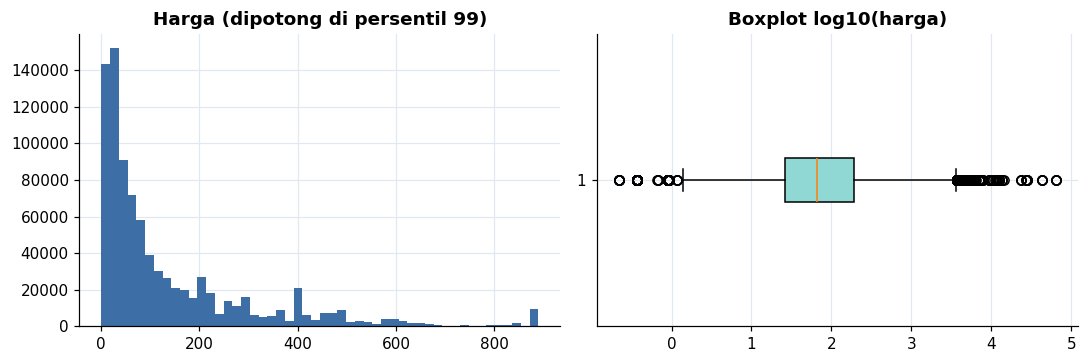

In [42]:
q1, q3 = raw['price'].quantile([.25, .75]); hi = q3 + 1.5 * (q3 - q1)
n_out = int((raw['price'] > hi).sum())
print(f'Batas atas IQR: {hi:,.1f} | baris di atas batas: {n_out:,} ({n_out / len(raw):.1%})')
print('Median harga:', round(raw['price'].median(), 2), '| maksimum:', f"{raw['price'].max():,.0f}")
print('Persentil 99 dan 99,9:', raw['price'].quantile([.99, .999]).round(1).tolist())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(raw['price'].clip(upper=raw['price'].quantile(.99)), bins=50, color=PRIMARY)
ax[0].set_title('Harga (dipotong di persentil 99)')
ax[1].boxplot(np.log10(raw['price']), vert=False, patch_artist=True, boxprops=dict(facecolor=LIGHT))
ax[1].set_title('Boxplot log10(harga)')
plt.tight_layout(); plt.savefig(f'{OUT}/outlier_harga.png'); plt.show()

**Keputusan outlier:** harga tinggi dianggap sah (komponen premium dan perangkat mahal), jadi baris **tidak dihapus**. Analisis memakai log harga, kuintil harga, dan harga relatif terhadap median kategori, sehingga nilai ekstrem tidak mendominasi.

### Data Cleaning
Urutan langkah, dengan jumlah baris yang terdampak dicatat di tabel kontrol:
1. **Duplikat** dihapus (baris identik pada 8 kolom yang dipakai).
2. **Harga kosong, nol, atau negatif** dibuang.
3. **Waktu** dikonversi ke `datetime` UTC; baris tanpa waktu valid atau tanpa `user_session` dibuang.
4. **Nilai kosong `category_code` dan `brand` dihapus** (tidak diisi `unknown`). Placeholder teks seperti "unknown", "null", atau "n/a" diperlakukan sebagai kosong.
5. **Penjaga integritas funnel:** nilai kosong konstan per produk, jadi penghapusan membuang semua event produk itu. Jika yang terhapus adalah event `cart` atau `purchase`, sesinya akan tampak seperti sesi view-only padahal aslinya tidak. Sesi seperti itu dikeluarkan seluruhnya agar funnel tidak bias.
6. **Outlier harga** dipertahankan (lihat keputusan di atas).

**Output data:** satu file `events_cleaned.csv` (tanpa nilai kosong) dan semua grafik PNG di folder `powerbi_export`.

In [43]:
n_raw = len(raw)

# 1. Duplikat
ev = raw.drop_duplicates()
n_dup = n_raw - len(ev)

# 2. Harga kosong, nol, atau negatif
n_price_bad = int((ev['price'].isna() | (ev['price'] <= 0)).sum())
ev = ev[ev['price'] > 0].copy()

# 3. Waktu dan sesi tidak valid
ev['t'] = pd.to_datetime(ev['event_time'], utc=True, errors='coerce')
n_bad = int(ev[['t', 'user_session']].isna().any(axis=1).sum())
ev = ev.dropna(subset=['t', 'user_session']).drop(columns='event_time')

# 4. Nilai kosong kategori dan brand dihapus (placeholder teks dianggap kosong)
MISSING_VALUES = {'', 'unknown', 'null', 'none', 'nan', 'n/a', 'na'}
for col in ['category_code', 'brand']:
    s = ev[col].astype('string').str.strip()
    ev[col] = s.mask(s.str.casefold().isin(MISSING_VALUES), pd.NA)
miss_dim = ev['category_code'].isna() | ev['brand'].isna()
n_null = int(miss_dim.sum())
sess_before = ev['user_session'].nunique()
lost_sessions = ev.loc[miss_dim & ev['event_type'].isin(['cart', 'purchase']), 'user_session'].unique()
ev = ev[~miss_dim]

# 5. Penjaga integritas funnel: keluarkan sesi yang event cart/purchase-nya ikut terhapus
in_lost = ev['user_session'].isin(lost_sessions)
n_integ_events = int(in_lost.sum()); n_integ_sessions = ev.loc[in_lost, 'user_session'].nunique()
ev = ev[~in_lost].copy()

# Snapshot event-level bersih untuk diekspor (tanpa nilai kosong)
events_cleaned_export = ev.rename(columns={'t': 'event_time'})[
    ['event_time', 'event_type', 'product_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']].copy()

qc = pd.Series({
    'Baris awal': n_raw,
    'Duplikat dihapus': -n_dup,
    'Harga kosong, nol, atau negatif dibuang': -n_price_bad,
    'Waktu atau sesi tidak valid dibuang': -n_bad,
    'Kategori atau brand kosong dihapus': -n_null,
    'Event dari sesi dengan cart/purchase terhapus': -n_integ_events,
    'Baris event bersih (ev)': len(ev)})
display(qc.map('{:,}'.format).to_frame('jumlah'))
print(f"Event dipertahankan: {len(ev) / n_raw:.1%} dari baris awal | sesi bersih: {ev['user_session'].nunique():,} "
      f"(sebelum penghapusan null: {sess_before:,})")
print(f'Sesi dikeluarkan oleh penjaga integritas: {n_integ_sessions:,}')
print('Sisa nilai kosong:', int(ev[['category_code', 'brand', 'price', 'user_id', 'user_session']].isna().sum().sum()))

,jumlah
Baris awal,"885,129"
Duplikat dihapus,-655
"Harga kosong, nol, atau negatif dibuang",0
Waktu atau sesi tidak valid dibuang,-162
Kategori atau brand kosong dihapus,"-368,457"
Event dari sesi dengan cart/purchase terhapus,"-17,656"
Baris event bersih (ev),"498,199"


Event dipertahankan: 56.3% dari baris awal | sesi bersih: 271,049 (sebelum penghapusan null: 490,398)
Sesi dikeluarkan oleh penjaga integritas: 2,372
Sisa nilai kosong: 0


**Insight:** penghapusan nilai kosong adalah langkah dengan dampak terbesar: 368.457 baris (41,6% dari data awal) dibuang, ditambah 17.656 event dari 2.372 sesi yang event keranjang atau pembeliannya ikut terhapus. Tersisa 498.199 event (56,3%) dari 271.049 sesi, tanpa nilai kosong.

### Dampak Penghapusan Nilai Kosong terhadap Representasi Data
Penghapusan membuang produk tanpa kategori atau brand. Jika perilaku sesi pada produk itu berbeda, hasil analisis hanya berlaku untuk **produk yang datanya lengkap**. Tabel berikut membandingkan konversi sesi yang dibuang dengan yang dipertahankan.

In [44]:
def session_funnel(e):
    p = e.groupby(['user_session', 'event_type']).size().unstack(fill_value=0)
    for k in ['view', 'cart', 'purchase']:
        if k not in p: p[k] = 0
    v = p['view'] > 0; c = v & (p['cart'] > 0); b = c & (p['purchase'] > 0)
    return pd.Series({'sesi_lihat': int(v.sum()), 'sesi_keranjang': int(c.sum()), 'sesi_beli_dari_keranjang': int(b.sum()),
                      'lihat_ke_keranjang_%': c.sum() / v.sum() * 100, 'keranjang_ke_beli_%': b.sum() / c.sum() * 100,
                      'konversi_lihat_ke_beli_%': b.sum() / v.sum() * 100})

# Pembanding: basis sebelum penghapusan null (setelah langkah 1 sampai 3)
ev_all = raw.drop_duplicates()
ev_all = ev_all[ev_all['price'] > 0].dropna(subset=['user_session'])
kept = ev_all.index.isin(events_cleaned_export.index)
bias = pd.DataFrame({'Sebelum hapus null (semua)': session_funnel(ev_all),
                     'Sesudah hapus null (dipakai)': session_funnel(ev),
                     'Sesi yang terbuang': session_funnel(ev_all[~kept])})
display(bias.round(2))

,Sebelum hapus null (semua),Sesudah hapus null (dipakai),Sesi yang terbuang
sesi_lihat,488360.00,269858.00,231676.00
sesi_keranjang,41256.00,24952.00,16304.00
sesi_beli_dari_keranjang,20754.00,12296.00,8458.00
lihat_ke_keranjang_%,8.45,9.25,7.04
keranjang_ke_beli_%,50.31,49.28,51.88
konversi_lihat_ke_beli_%,4.25,4.56,3.65


**Insight:** sesi yang dibuang berkonversi lebih rendah (3,65% vs 4,56% pada sesi yang dipakai) karena lebih jarang ke keranjang (7,04% vs 9,25%). Akibatnya konversi pada data bersih sedikit lebih tinggi daripada seluruh toko (4,56% vs 4,25%), dan 41% sesi beli dari keranjang (8.458 dari 20.754) tidak ikut dianalisis. **Hasil berlaku untuk produk yang kategori dan brand-nya tercatat**, dan kelengkapan katalog tidak lagi bisa dianalisis sebagai faktor.

### Feature Engineering Dasar: Tabel Fakta Sesi × Kategori × Brand
| Fitur | Sumber | Tujuan |
|---|---|---|
| `category_main` | bagian pertama `category_code` | kategori utama produk |
| `viewed`, `carted`, `purchased` | `event_type` | flag funnel per baris fakta |
| `cart_value`, `revenue` | `price` pada event cart / purchase | nilai keranjang dan pendapatan |
| `date`, `hour`, `dow` | `first_time` | waktu kunjungan (zona `TZ`) |

Tabel `fact` hanya dibuat di memori untuk funnel dan lampiran; tidak diekspor.

In [45]:
ev['category_main'] = ev['category_code'].str.split('.').str[0]
ev['viewed'] = (ev['event_type'] == 'view').astype('int8')
ev['carted'] = (ev['event_type'] == 'cart').astype('int8')
ev['purchased'] = (ev['event_type'] == 'purchase').astype('int8')
ev['cart_value'] = ev['price'].where(ev['carted'] == 1, 0.0)
ev['revenue'] = ev['price'].where(ev['purchased'] == 1, 0.0)

fact = (ev.groupby(['user_session', 'category_main', 'brand'], observed=True)
          .agg(user_id=('user_id', 'first'), first_time=('t', 'min'),
               viewed=('viewed', 'max'), carted=('carted', 'max'), purchased=('purchased', 'max'),
               cart_value=('cart_value', 'sum'), revenue=('revenue', 'sum'))
          .reset_index())
loc = fact['first_time'].dt.tz_convert(TZ)
fact['date'] = loc.dt.date
fact['hour'] = loc.dt.hour
fact['dow'] = loc.dt.dayofweek          # 0 = Senin
print('Baris fakta (sesi x kategori x brand):', f'{len(fact):,}')
display(fact.head())

Baris fakta (sesi x kategori x brand): 313,041


,user_session,category_main,brand,user_id,first_time,viewed,carted,purchased,cart_value,revenue,date,hour,dow
0,000c34fa-991f-442a-8e07-8c472269bec6,electronics,xiaomi,1515915625509232600,2020-09-30 17:52:02+00:00,1,0,0,0.0,0.0,2020-09-30,17,2
1,001P7lK0Pt,electronics,samsung,1515915625536141302,2020-11-06 01:25:43+00:00,1,0,0,0.0,0.0,2020-11-06,1,4
2,001RxUtFJa,computers,asus,1515915625570256322,2020-12-29 04:50:33+00:00,1,0,0,0.0,0.0,2020-12-29,4,1
3,002DmERG1w,computers,d-color,1515915625520065148,2020-09-26 18:59:06+00:00,1,0,0,0.0,0.0,2020-09-26,18,5
4,003pEktS1X,stationery,cactus,1515915625533857816,2020-11-02 18:11:24+00:00,1,0,0,0.0,0.0,2020-11-02,18,0


### Kualitas `user_session` dan Uji Sensitivitas (jeda 30 menit)
Dokumentasi dataset menyebut `user_session` berubah setelah jeda panjang, tetapi tidak menyebut batasnya. Kualitasnya diperiksa, lalu funnel dihitung ulang dengan sesi yang dibangun ulang memakai jeda 30 menit (standar umum analitik web).

In [46]:
spu = ev.groupby('user_id')['user_session'].nunique()
g = ev.groupby('user_session').agg(n=('t', 'size'), t0=('t', 'min'), t1=('t', 'max'))
g['dur_s'] = (g['t1'] - g['t0']).dt.total_seconds()
q = {'Pengguna dengan 1 user_session (%)': (spu == 1).mean() * 100,
     'Median event per sesi': g['n'].median(),
     'Persentil 99 event per sesi': g['n'].quantile(.99),
     'Sesi dengan 100 event atau lebih': int((g['n'] >= 100).sum()),
     'Sesi berdurasi lebih dari 30 menit (%)': (g['dur_s'] > 1800).mean() * 100,
     'Sesi berdurasi lebih dari 1 hari (%)': (g['dur_s'] > 86400).mean() * 100}
display(pd.Series(q).round(2).to_frame('nilai'))

,nilai
Pengguna dengan 1 user_session (%),87.15
Median event per sesi,1.00
Persentil 99 event per sesi,11.00
Sesi dengan 100 event atau lebih,12.00
Sesi berdurasi lebih dari 30 menit (%),6.48
Sesi berdurasi lebih dari 1 hari (%),2.14


In [47]:
e30 = ev[['user_id', 'user_session', 'event_type', 't']].sort_values(['user_id', 't']).copy()
gap = e30.groupby('user_id')['t'].diff()
e30['new'] = gap.isna() | (gap > pd.Timedelta(minutes=30))
e30['session_id'] = e30['user_id'].astype(str) + '_' + e30.groupby('user_id')['new'].cumsum().astype(str)

def funnel_stats(key):
    p = e30.groupby([key, 'event_type'])['t'].min().unstack()
    v = p['view'].notna()
    c = v & p['cart'].notna()
    b = c & p['purchase'].notna()
    return {'sesi_lihat': int(v.sum()), 'sesi_keranjang': int(c.sum()), 'sesi_beli_dari_keranjang': int(b.sum()),
            'lihat_ke_keranjang_%': c.sum() / v.sum() * 100, 'keranjang_ke_beli_%': b.sum() / c.sum() * 100,
            'konversi_lihat_ke_beli_%': b.sum() / v.sum() * 100}

sens = pd.DataFrame({'user_session (asli)': funnel_stats('user_session'),
                     'session_id (jeda 30 menit)': funnel_stats('session_id')})
display(sens.round(2))

,user_session (asli),session_id (jeda 30 menit)
sesi_lihat,269858.00,279720.00
sesi_keranjang,24952.00,25560.00
sesi_beli_dari_keranjang,12296.00,12839.00
lihat_ke_keranjang_%,9.25,9.14
keranjang_ke_beli_%,49.28,50.23
konversi_lihat_ke_beli_%,4.56,4.59


**Insight:** 87,1% pengguna hanya punya satu `user_session`, 6,5% sesi berlangsung lebih dari 30 menit, dan 2,1% mencakup lebih dari satu hari. Dengan sesi jeda 30 menit, konversi lihat ke beli 4,59% (vs 4,56%) dan keranjang ke beli 50,2% (vs 49,3%). Selisih kecil, jadi unit utama tetap `user_session` dan hasil 30 menit dilaporkan sebagai uji sensitivitas.

In [48]:
# @title Banner Section 02 · BQ1
banner('Section 02 · BQ1', 'Seberapa Besar Masalahnya dan di Mana Sesi Hilang?',
       'Funnel lihat → keranjang → beli, dekomposisi konversi, pembentukan tabel diagnosis, dan KPI.',
       accent='#34D399', end='#047857')

### 2a. Funnel Sesi: Lihat Produk → Beli dari Keranjang

,sesi
Lihat produk,"269,858"
Tambah ke keranjang,"24,952"
Beli dari keranjang,"12,296"


Lihat->Keranjang 9.2% | Keranjang->Beli 49.3% | KONVERSI LIHAT->BELI (via keranjang) 4.56%
Tidak berkonversi: 95.4% sesi = tidak ke keranjang 90.8% + keranjang ditinggalkan 4.7%
Sesi beli tanpa event keranjang: 900 (6.8% dari semua sesi beli)


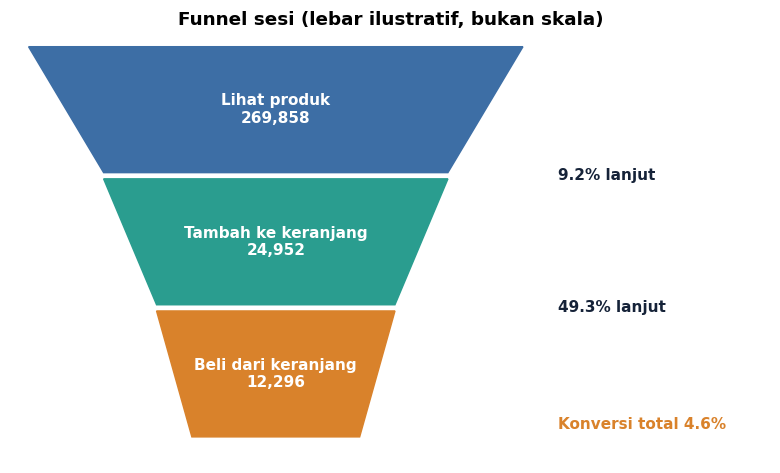

In [49]:
sess = fact.groupby('user_session').agg(viewed=('viewed', 'max'), carted=('carted', 'max'), purchased=('purchased', 'max'))
sv = sess[sess['viewed'] == 1]                      # funnel nested: hanya sesi yang punya view
n_view = len(sv); n_cart = int(sv['carted'].sum())
n_cart_buy = int(((sv['carted'] == 1) & (sv['purchased'] == 1)).sum()); n_buy_all = int(sv['purchased'].sum())
funnel = pd.Series({'Lihat produk': n_view, 'Tambah ke keranjang': n_cart, 'Beli dari keranjang': n_cart_buy})
r_vc = n_cart / n_view; r_cp = n_cart_buy / n_cart; r_vb = n_cart_buy / n_view      # r_vb = konversi lihat -> beli (utama)

display(funnel.map('{:,}'.format).to_frame('sesi'))
print(f'Lihat->Keranjang {r_vc:.1%} | Keranjang->Beli {r_cp:.1%} | KONVERSI LIHAT->BELI (via keranjang) {r_vb:.2%}')
print(f'Tidak berkonversi: {1 - r_vb:.1%} sesi = tidak ke keranjang {(n_view - n_cart) / n_view:.1%} + keranjang ditinggalkan {(n_cart - n_cart_buy) / n_view:.1%}')
print(f'Sesi beli tanpa event keranjang: {n_buy_all - n_cart_buy:,} ({(n_buy_all - n_cart_buy) / n_buy_all:.1%} dari semua sesi beli)')

from matplotlib.patches import Polygon
fig, ax = plt.subplots(figsize=(7.2, 4.4)); W = [5.6, 3.9, 2.7, 1.9]; cols = [BLUE, '#2A9D8F', ORANGE]
for k in range(3):
    y0 = -k * 1.05; top, bot = W[k], W[k + 1]
    ax.add_patch(Polygon([(-top / 2, y0), (top / 2, y0), (bot / 2, y0 - 1), (-bot / 2, y0 - 1)], color=cols[k]))
    ax.text(0, y0 - 0.5, f'{funnel.index[k]}\n{funnel.values[k]:,.0f}', ha='center', va='center', color='white', fontsize=10, fontweight='bold')
ax.text(3.2, -1.02, f'{r_vc:.1%} lanjut', ha='left', va='center', fontsize=10, color=NAVY, fontweight='bold')
ax.text(3.2, -2.07, f'{r_cp:.1%} lanjut', ha='left', va='center', fontsize=10, color=NAVY, fontweight='bold')
ax.text(3.2, -3.0, f'Konversi total {r_vb:.1%}', ha='left', va='center', fontsize=10, color=ORANGE, fontweight='bold')
ax.set_xlim(-3, 5.6); ax.set_ylim(-3.3, 0.1); ax.axis('off'); ax.set_title('Funnel sesi (lebar ilustratif, bukan skala)')
plt.tight_layout(); plt.savefig(f'{OUT}/funnel.png'); plt.show()

**Insight:** dari 269.858 sesi dengan view, 9,2% menambah ke keranjang dan 49,3% dari sesi berkeranjang lanjut membeli, sehingga konversi lihat ke beli hanya **4,56%**. Dari 95,4% sesi yang tidak berkonversi, 90,8% tidak pernah ke keranjang dan 4,7% meninggalkan keranjang. Kebocoran terbesar ada di awal funnel, tetapi tahap keranjang ke beli juga kehilangan separuh sesi. Sekitar 6,8% sesi beli (900 sesi) tidak punya event keranjang.

### 2b. Membentuk Tabel Sesi untuk Diagnosis (basis `d`)
Fitur dihitung hanya dari view **sebelum atau saat** keranjang atau pembelian pertama, supaya aktivitas pasca-keputusan tidak membocorkan hasil ke fitur. Sesi beli tanpa keranjang dikeluarkan karena tidak termasuk jalur "beli dari keranjang". Target utama `bought` = 1 untuk sesi yang membeli dari keranjang.

In [50]:
t_cart = ev[ev['event_type'] == 'cart'].groupby('user_session')['t'].min().rename('tc')
t_buy = ev[ev['event_type'] == 'purchase'].groupby('user_session')['t'].min().rename('tp')
allv = ev[ev['event_type'] == 'view']
v = allv.join(t_cart, on='user_session').join(t_buy, on='user_session')
v = v[(v['tc'].isna() | (v['t'] <= v['tc'])) & (v['tp'].isna() | (v['t'] <= v['tp']))]   # view sebelum atau saat keputusan

med_cat = allv.groupby('category_main')['price'].median()
v['price_rel'] = v['price'] / v['category_main'].map(med_cat)                              # harga relatif terhadap median kategori
v['pop'] = np.log10(v['product_id'].map(allv.groupby('product_id').size()))               # popularitas produk (log10 jumlah view)

d = v.groupby('user_session').agg(
    n_views=('product_id', 'size'), n_products=('product_id', 'nunique'), avg_price=('price', 'mean'),
    price_rel=('price_rel', 'mean'), pop=('pop', 'mean'), category=('category_main', 'first'),
    t0=('t', 'min'), t1=('t', 'max'), user_id=('user_id', 'first'))
rep = v.groupby(['user_session', 'product_id']).size().groupby('user_session').max()
d['repeat'] = (rep >= 2).astype(int)                                                       # produk yang sama dilihat berulang
d['minutes'] = (d['t1'] - d['t0']).dt.total_seconds() / 60
loc0 = d['t0'].dt.tz_convert(TZ)
d['hour'] = loc0.dt.hour; d['dow'] = loc0.dt.dayofweek; d['weekend'] = (d['dow'] >= 5).astype(int)
d['carted'] = d.index.isin(t_cart.index).astype(int); d['bought_any'] = d.index.isin(t_buy.index).astype(int)

st = (ev.drop_duplicates('user_session')[['user_session', 'user_id']].set_index('user_session')
        .join(ev.groupby('user_session')['t'].min().rename('ts')))
st['idx'] = st.sort_index().sort_values('ts', kind='stable').groupby('user_id').cumcount()   # urutan stabil agar hasil deterministik
d['returning'] = (d.index.map(st['idx']) > 0).astype(int)                                  # sesi ke-2 atau lebih milik pengguna di data

n_buy_nocart = int(((d['carted'] == 0) & (d['bought_any'] == 1)).sum())
d = d[~((d['carted'] == 0) & (d['bought_any'] == 1))].copy()                               # sesi beli tanpa keranjang dikeluarkan
d['bought'] = d['bought_any']                                                              # setelah pengecualian, pembeli pasti lewat keranjang
d['abandon'] = ((d['carted'] == 1) & (d['bought'] == 0)).astype(int)
d['view_only'] = 1 - d['carted']; d['single'] = (d['n_views'] == 1).astype(int)
N = len(d); NB = int(d['bought'].sum()); NC = int(d['carted'].sum()); VO = int(d['view_only'].sum()); AB = int(d['abandon'].sum())
BOUNCE = int(((d['single'] == 1) & (d['view_only'] == 1)).sum())
avg_buy = NB / N * 100; avg_cart = NC / N * 100

# Pemeriksaan urutan: berapa sesi pembeli yang pembelian pertamanya terjadi sebelum keranjang pertama?
both = t_cart.index.intersection(t_buy.index)
pre = int((t_buy.loc[both] < t_cart.loc[both]).sum())

print(f'Sesi dianalisis: {N:,} (dikeluarkan: {n_buy_nocart:,} sesi beli tanpa keranjang)')
print(f'Beli dari keranjang: {NB:,} ({NB / N:.2%}) | ke keranjang: {NC:,} ({NC / N:.1%}) | beli | keranjang: {NB / NC:.1%}')
print(f'Tidak membeli: {N - NB:,} ({1 - NB / N:.1%}) = view-only {VO:,} ({VO / N:.1%}, bounce {BOUNCE / N:.1%} dari semua sesi) + keranjang ditinggalkan {AB:,} ({AB / N:.1%})')
print(f'Sesi dengan pembelian pertama sebelum keranjang pertama: {pre:,} ({pre / len(both):.2%} dari sesi keranjang+beli)')

def rate_table(x):
    """Tiga angka per kelompok x: ke keranjang, beli (lihat->beli), dan beli | keranjang."""
    g = d.groupby(x, observed=True).agg(sesi=('bought', 'size'), n_cart=('carted', 'sum'), n_buy=('bought', 'sum'))
    g['porsi_sesi_%'] = (g['sesi'] / N * 100).round(1)
    g['keranjang_%'] = (g['n_cart'] / g['sesi'] * 100).round(1)
    g['beli_%'] = (g['n_buy'] / g['sesi'] * 100).round(2)
    g['beli_dari_keranjang_%'] = (g['n_buy'] / g['n_cart'].replace(0, np.nan) * 100).round(1)
    return g[['sesi', 'porsi_sesi_%', 'keranjang_%', 'beli_%', 'beli_dari_keranjang_%']]

Sesi dianalisis: 268,874 (dikeluarkan: 694 sesi beli tanpa keranjang)
Beli dari keranjang: 12,216 (4.54%) | ke keranjang: 24,868 (9.2%) | beli | keranjang: 49.1%
Tidak membeli: 256,658 (95.5%) = view-only 244,006 (90.8%, bounce 70.6% dari semua sesi) + keranjang ditinggalkan 12,652 (4.7%)
Sesi dengan pembelian pertama sebelum keranjang pertama: 144 (1.17% dari sesi keranjang+beli)


**Catatan basis:** `d` berisi 268.874 sesi, yaitu 269.858 sesi funnel dikurangi 694 sesi beli tanpa keranjang dan 290 sesi tanpa view sebelum keputusan. Konversi lihat ke beli pada basis ini 4,54% (12.216 sesi), sedikit berbeda dari 4,56% di funnel karena perbedaan basis itu. Hanya 1,17% sesi pembeli yang pembelian pertamanya mendahului keranjang pertama, jadi definisi "beli dari keranjang" pada level sesi aman.

### 2c. KPI Konversi Sesi

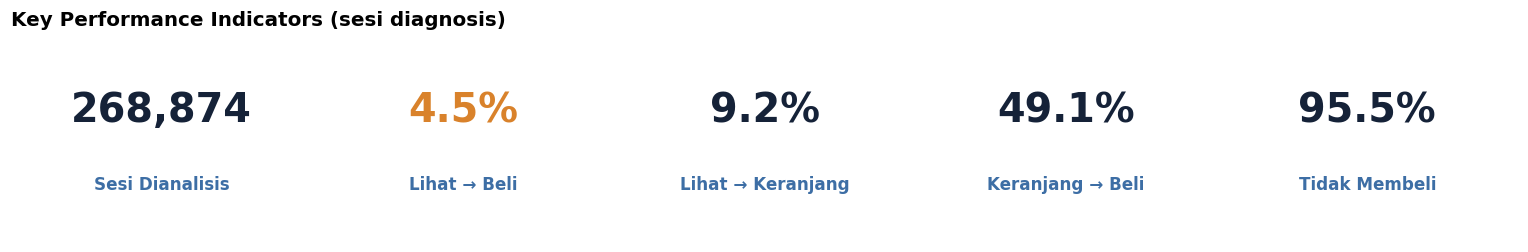

In [51]:
kpis = [('Sesi Dianalisis', f'{N:,}'), ('Lihat → Beli', f'{NB / N:.1%}'), ('Lihat → Keranjang', f'{NC / N:.1%}'),
        ('Keranjang → Beli', f'{NB / NC:.1%}'), ('Tidak Membeli', f'{1 - NB / N:.1%}')]
fig, ax = plt.subplots(figsize=(14, 2.4)); ax.axis('off')
for i, (lab, val) in enumerate(kpis):
    x = 0.1 + i * 0.2
    ax.text(x, 0.58, val, ha='center', fontsize=26, fontweight='bold', color=ORANGE if i == 1 else NAVY, transform=ax.transAxes)
    ax.text(x, 0.25, lab, ha='center', fontsize=11, fontweight='bold', color=BLUE, transform=ax.transAxes)
ax.set_title('Key Performance Indicators (sesi diagnosis)', fontsize=13, fontweight='bold', loc='left')
plt.tight_layout(); plt.savefig(f'{OUT}/kpi.png'); plt.show()

**Insight:** 95,5% dari 268.874 sesi tidak membeli: 90,8% view-only (70,6% dari semua sesi adalah bounce, yaitu satu event view lalu pergi) dan 4,7% meninggalkan keranjang. Konversi lihat ke beli 4,5% adalah hasil kali dua tahap: 9,2% ke keranjang × 49,1% beli dari keranjang.

#### Kesimpulan BQ1
Masalahnya ada di dua titik: sembilan dari sepuluh sesi tidak pernah ke keranjang, dan separuh sesi berkeranjang tidak membeli. Perbaikan di awal funnel menyentuh basis sesi yang jauh lebih besar, sedangkan perbaikan di tahap keranjang menyentuh sesi yang sudah menunjukkan niat beli. Pertanyaan berikutnya adalah siapa yang tidak membeli.

In [52]:
# @title Banner Section 03 · BQ2
banner('Section 03 · BQ2', 'Siapa yang Tidak Membeli?',
       'Konversi lihat → beli menurut kedalaman browsing, kunjungan pertama vs kembali, dan segmen gabungannya.',
       accent='#FBBF24', end='#B45309')

### 3a. Kedalaman Browsing

,sesi,porsi_sesi_%,keranjang_%,beli_%,beli_dari_keranjang_%
views_bin,,,,,
1,206379,76.8,8.0,3.91,49.0
2,37318,13.9,12.1,5.84,48.4
3,12096,4.5,14.4,7.07,49.0
4-5,7865,2.9,15.7,7.72,49.0
6-10,3916,1.5,16.9,9.27,54.8
>10,1300,0.5,17.4,10.08,58.0


,sesi,porsi_sesi_%,keranjang_%,beli_%,beli_dari_keranjang_%
prod_bin,,,,,
1,233269,86.8,8.4,4.16,49.4
2,22628,8.4,13.9,6.60,47.6
3,6496,2.4,15.5,7.05,45.3
4-5,4050,1.5,16.0,8.27,51.6
6-10,1926,0.7,16.6,8.62,52.0
>10,505,0.2,17.0,10.30,60.5


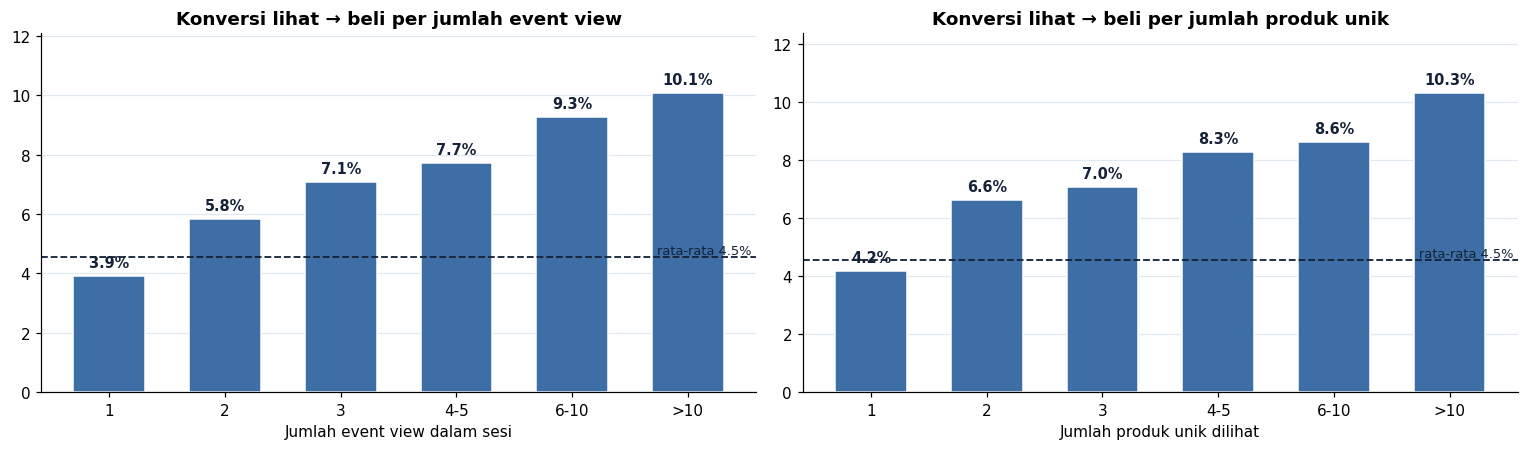

In [53]:
d['views_bin'] = pd.cut(d['n_views'], [0, 1, 2, 3, 5, 10, np.inf], labels=['1', '2', '3', '4-5', '6-10', '>10'])
d['prod_bin'] = pd.cut(d['n_products'], [0, 1, 2, 3, 5, 10, np.inf], labels=['1', '2', '3', '4-5', '6-10', '>10'])
t_views, t_prod = rate_table('views_bin'), rate_table('prod_bin')
display(t_views); display(t_prod)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
bar_labeled(axes[0], t_views.index.astype(str), t_views['beli_%'].values, ref=avg_buy, fmt='{:.1f}%')
axes[0].set_title('Konversi lihat → beli per jumlah event view'); axes[0].set_xlabel('Jumlah event view dalam sesi')
bar_labeled(axes[1], t_prod.index.astype(str), t_prod['beli_%'].values, ref=avg_buy, fmt='{:.1f}%')
axes[1].set_title('Konversi lihat → beli per jumlah produk unik'); axes[1].set_xlabel('Jumlah produk unik dilihat')
plt.tight_layout(); plt.savefig(f'{OUT}/kedalaman.png'); plt.show()

**Insight:** 76,8% sesi hanya punya satu event view dan berkonversi 3,9%. Konversi naik ke 5,8% pada 2 view dan 10,1% pada lebih dari 10 view. Kenaikan terutama berasal dari tahap lihat ke keranjang (8,0% → 17,4%); keranjang ke beli baru naik pada 6 view atau lebih (54,8% dan 58,0% vs sekitar 49%). Pola produk unik serupa: 1 produk 4,2% dan lebih dari 10 produk 10,3%.

### 3b. Kunjungan Pertama vs Kembali, dan Segmen Gabungan

,sesi,porsi_sesi_%,keranjang_%,beli_%,beli_dari_keranjang_%
returning,,,,,
0,222670,82.8,7.8,3.68,46.8
1,46204,17.2,16.0,8.73,54.5


sesi  porsi_sesi_%  keranjang_%  beli_%  beli_dari_keranjang_%
single returning                                                                  
0      0           50236          18.7         12.1    5.79                   47.8
       1           12259           4.6         18.7   10.03                   53.6
1      0          172434          64.1          6.6    3.06                   46.3
       1           33945          12.6         15.0    8.26                   54.9

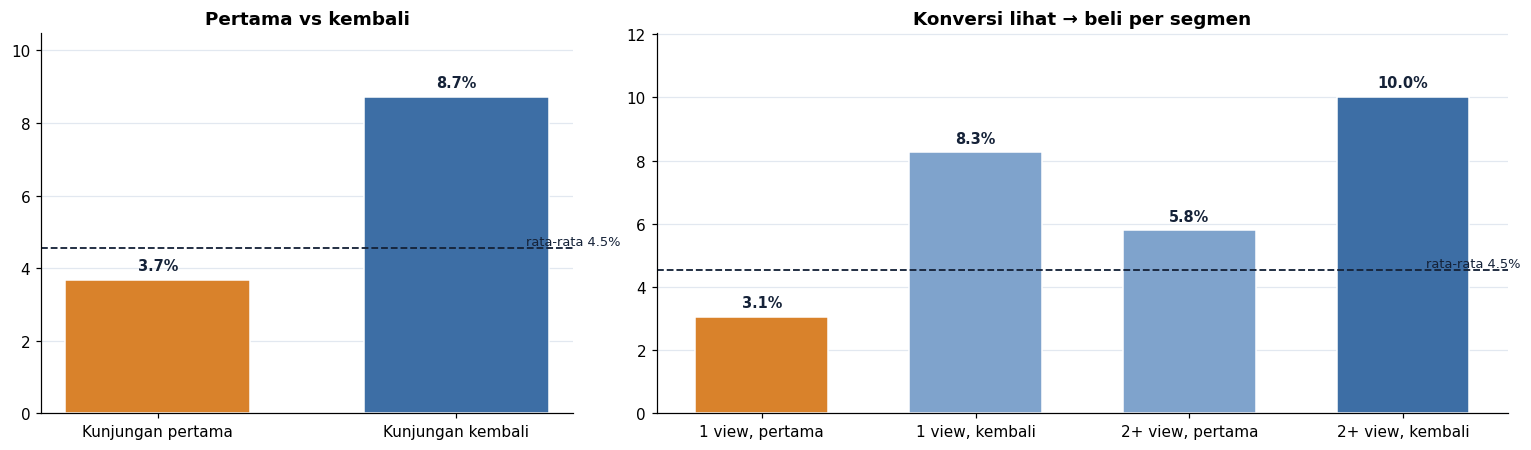

In [54]:
t_ret = rate_table('returning'); display(t_ret)
seg_t = rate_table(['single', 'returning']); display(seg_t)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [1, 1.6]})
bar_labeled(axes[0], ['Kunjungan pertama', 'Kunjungan kembali'], t_ret['beli_%'].values, colors=[ORANGE, BLUE], ref=avg_buy)
axes[0].set_title('Pertama vs kembali')
lab = ['1 view, pertama', '1 view, kembali', '2+ view, pertama', '2+ view, kembali']
vals = [seg_t.loc[(1, 0), 'beli_%'], seg_t.loc[(1, 1), 'beli_%'], seg_t.loc[(0, 0), 'beli_%'], seg_t.loc[(0, 1), 'beli_%']]
bar_labeled(axes[1], lab, vals, colors=[ORANGE, '#7FA3CC', '#7FA3CC', BLUE], ref=avg_buy)
axes[1].set_title('Konversi lihat → beli per segmen')
plt.tight_layout(); plt.savefig(f'{OUT}/siapa_tidak_membeli.png'); plt.show()

**Insight:** kunjungan kembali berkonversi 8,7% vs 3,7% pada kunjungan pertama, karena lebih sering ke keranjang (16,0% vs 7,8%) dan lebih sering membeli dari keranjang (54,5% vs 46,8%). Segmen terbesar adalah kunjungan pertama dengan 1 view: 64,1% sesi dengan konversi 3,1%. Segmen terbaik, kunjungan kembali dengan 2+ view, mencapai 10,0%.

#### Kesimpulan BQ2
Sesi yang tidak membeli didominasi kunjungan pertama dengan satu produk. Kedalaman browsing dan kunjungan kembali berasosiasi dengan konversi 2 sampai 3 kali lebih tinggi. Karena pengunjung yang berniat membeli juga cenderung menjelajah dan kembali, ini asosiasi dan bukan bukti sebab-akibat; perlu A/B test.

In [55]:
# @title Banner Section 04 · BQ3
banner('Section 04 · BQ3', 'Apa yang Dilihat dan Kapan Mereka Berkunjung?',
       'Popularitas produk, kategori, harga, dan waktu kunjungan, diukur pada konversi lihat → beli.',
       accent='#A855F7', end='#6D28D9')

### 4a. Popularitas Produk dan Kategori

,sesi,porsi_sesi_%,keranjang_%,beli_%,beli_dari_keranjang_%
pop_q,,,,,
Q1 paling jarang dilihat,68571,25.5,4.5,2.23,49.9
Q2,65867,24.5,6.6,3.33,50.3
Q3,67248,25.0,9.4,4.90,52.0
Q4 paling populer,67188,25.0,16.5,7.73,46.8


,sesi,porsi_sesi_%,keranjang_%,beli_%,beli_dari_keranjang_%
category,,,,,
computers,121862,45.3,13.2,6.32,48.0
stationery,19691,7.3,8.5,5.00,58.8
auto,16478,6.1,6.4,3.22,50.6
construction,11047,4.1,6.1,2.89,47.1
electronics,75094,27.9,5.9,2.87,48.9
appliances,20865,7.8,4.3,2.24,52.7


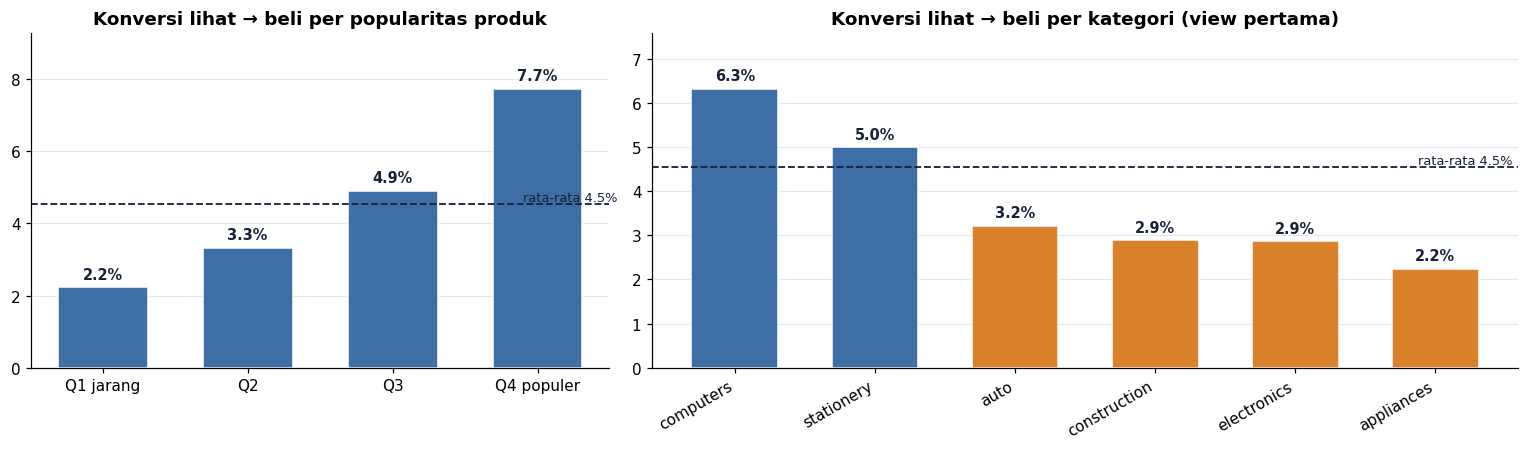

In [56]:
d['pop_q'] = pd.qcut(d['pop'], 4, labels=['Q1 paling jarang dilihat', 'Q2', 'Q3', 'Q4 paling populer'])
t_pop = rate_table('pop_q')
t_categ = rate_table('category'); t_categ = t_categ[t_categ['sesi'] >= MIN_CAT].sort_values('beli_%', ascending=False)
display(t_pop); display(t_categ)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [1, 1.5]})
bar_labeled(axes[0], ['Q1 jarang', 'Q2', 'Q3', 'Q4 populer'], t_pop['beli_%'].values, ref=avg_buy)
axes[0].set_title('Konversi lihat → beli per popularitas produk')
cols_c = [BLUE if x >= avg_buy else ORANGE for x in t_categ['beli_%']]
bar_labeled(axes[1], t_categ.index, t_categ['beli_%'].values, colors=cols_c, ref=avg_buy, rot=30)
axes[1].set_title('Konversi lihat → beli per kategori (view pertama)')
plt.tight_layout(); plt.savefig(f'{OUT}/apa_dilihat.png'); plt.show()

**Insight:** produk yang paling jarang dilihat berkonversi 2,2%, dibanding 7,7% untuk yang paling populer (2,2% → 3,3% → 4,9% → 7,7%). Produk populer jauh lebih sering masuk keranjang (16,5% vs 4,5%), tetapi keranjangnya paling sering ditinggalkan (46,8% beli, dibanding sekitar 50% pada kelompok lain). Komputer berkonversi 6,3% dan alat tulis 5,0%, sedangkan peralatan rumah 2,2% dan elektronik 2,9%.

### 4b. Harga

,sesi,porsi_sesi_%,keranjang_%,beli_%,beli_dari_keranjang_%
price_q,,,,,
Q1 termurah,53886,20.0,7.1,4.10,58.0
Q2,53664,20.0,7.0,3.61,51.7
Q3,54044,20.1,7.8,3.96,50.7
Q4,53646,20.0,11.6,5.39,46.4
Q5 termahal,53634,19.9,12.8,5.66,44.3


,sesi,porsi_sesi_%,keranjang_%,beli_%,beli_dari_keranjang_%
price_rel_q,,,,,
Q1 relatif murah,53827,20.0,6.1,3.40,55.7
Q2,53988,20.1,8.5,4.50,53.0
Q3,53520,19.9,9.3,4.73,50.8
Q4,53766,20.0,12.2,5.64,46.2
Q5 relatif mahal,53773,20.0,10.2,4.46,43.9


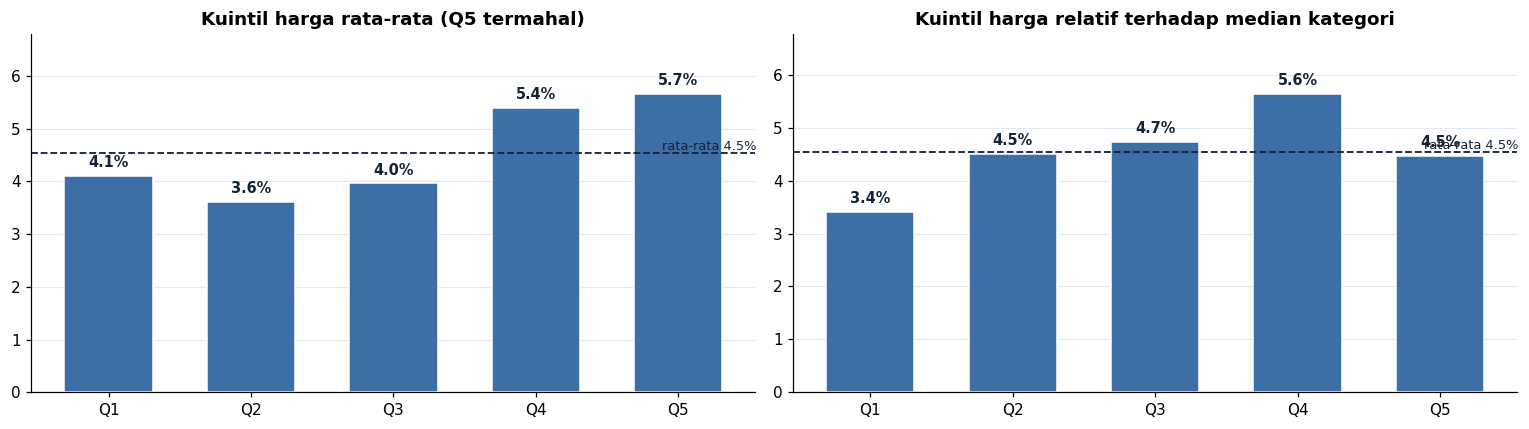

In [57]:
d['price_q'] = pd.qcut(d['avg_price'], 5, labels=['Q1 termurah', 'Q2', 'Q3', 'Q4', 'Q5 termahal'])
d['price_rel_q'] = pd.qcut(d['price_rel'], 5, labels=['Q1 relatif murah', 'Q2', 'Q3', 'Q4', 'Q5 relatif mahal'], duplicates='drop')
t_price, t_prel = rate_table('price_q'), rate_table('price_rel_q')
display(t_price); display(t_prel)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.0))
bar_labeled(axes[0], ['Q1', 'Q2', 'Q3', 'Q4', 'Q5'], t_price['beli_%'].values, ref=avg_buy)
axes[0].set_title('Kuintil harga rata-rata (Q5 termahal)')
bar_labeled(axes[1], ['Q1', 'Q2', 'Q3', 'Q4', 'Q5'], t_prel['beli_%'].values, ref=avg_buy)
axes[1].set_title('Kuintil harga relatif terhadap median kategori')
plt.tight_layout(); plt.savefig(f'{OUT}/harga.png'); plt.show()

**Insight:** konversi lihat ke beli naik dengan harga (Q1 4,1%, Q5 5,7%) karena sesi dengan produk mahal lebih sering ke keranjang (12,8% vs 7,1%). Di tahap keranjang ke beli arahnya berbalik: 58,0% pada kuintil termurah vs 44,3% pada termahal. Harga tampaknya bukan penghalang di awal funnel, tetapi berasosiasi dengan keranjang yang ditinggalkan.

### 4c. Waktu Kunjungan: Jam, Hari, dan Tren Mingguan

Konversi per jam: 3.5% sampai 5.0% | per hari: 4.3% sampai 4.7%
Konversi rata-rata: Sep sampai Okt 3.85% | Jan sampai Feb 5.12%


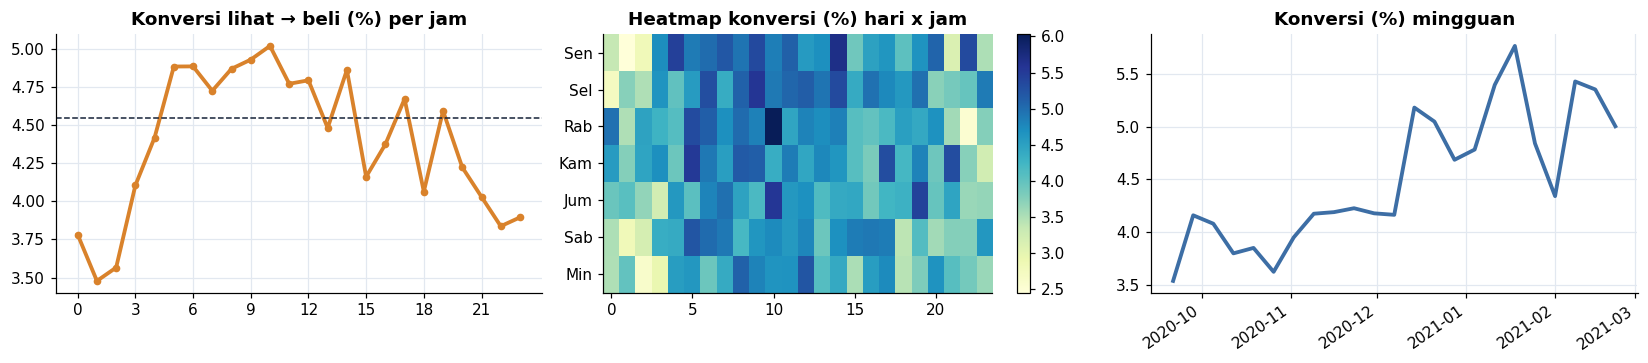

In [58]:
byh = d.groupby('hour')['bought'].agg(['mean', 'size']); byh['mean'] *= 100
heat = d.groupby(['dow', 'hour'])['bought'].mean().mul(100).unstack('hour').reindex(range(7))
byd = d.groupby('dow')['bought'].mean().mul(100)
print(f"Konversi per jam: {byh['mean'].min():.1f}% sampai {byh['mean'].max():.1f}% | per hari: {byd.min():.1f}% sampai {byd.max():.1f}%")
wk = d['t0'].dt.tz_convert(TZ).dt.tz_localize(None).dt.to_period('W').dt.start_time
weekly = d.groupby(wk)['bought'].agg(sesi='size', beli='mean')
w_early = d[wk < '2020-11-01']['bought'].mean() * 100; w_late = d[wk >= '2021-01-01']['bought'].mean() * 100
print(f'Konversi rata-rata: Sep sampai Okt {w_early:.2f}% | Jan sampai Feb {w_late:.2f}%')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].plot(byh.index, byh['mean'], color=ORANGE, lw=2.5, marker='o', ms=4); ax[0].axhline(avg_buy, color=NAVY, ls='--', lw=1)
ax[0].set_title('Konversi lihat → beli (%) per jam'); ax[0].set_xticks(range(0, 24, 3))
im = ax[1].imshow(heat.values, aspect='auto', cmap='YlGnBu')
ax[1].set_yticks(range(7)); ax[1].set_yticklabels(['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min'])
ax[1].set_title('Heatmap konversi (%) hari x jam'); ax[1].grid(False); plt.colorbar(im, ax=ax[1])
ax[2].plot(weekly.index, weekly['beli'] * 100, color=PRIMARY, lw=2.5)
ax[2].set_title('Konversi (%) mingguan'); plt.setp(ax[2].get_xticklabels(), rotation=35, ha='right')
plt.tight_layout(); plt.savefig(f'{OUT}/kapan.png'); plt.show()

**Insight:** konversi per jam 3,5% sampai 5,0% dan per hari 4,3% sampai 4,7% (UTC), jadi pengaruh waktu kecil. Tren mingguan naik dari sekitar 3,9% (Sep sampai Okt) ke 5,1% (Jan sampai Feb), dengan minggu pertama dan terakhir parsial; penyebabnya tidak bisa dipastikan dari data ini.

#### Kesimpulan BQ3
Yang membedakan adalah produk apa yang dilihat (popularitas dan kategori) dan harga di tahap keranjang, bukan jam atau hari. Produk ekor panjang berkonversi kurang dari sepertiga produk populer.

In [59]:
# @title Banner Section 05 · BQ4
banner('Section 05 · BQ4', 'Faktor Mana yang Paling Membedakan Pembeli?',
       'Regresi logistik untuk (a) lihat → beli pada semua sesi dan (b) keranjang → beli pada sesi berkeranjang, dengan uji buang-fitur dan buang-kelompok.',
       accent='#F87171', end='#B91C1C')

### 5a. Model Lihat → Beli (semua sesi)
Target `bought`. Fitur numerik berskala besar ditransformasi `log1p`, lalu distandarkan. Data dibagi 75:25 dengan stratifikasi. Kontribusi diukur dari **penurunan ROC-AUC pada data uji bila fitur (atau kelompok fitur) dibuang**, dengan model dilatih ulang. Uji per kelompok dipakai karena fitur kedalaman (`n_views`, `n_products`, `minutes`, `repeat`) saling berkorelasi, sehingga membuang satu fitur saja tampak kecil.

AUC lihat -> beli (data uji): 0.6888 | sesi: 268,874 | pembeli: 12,216


,penurunan AUC per fitur (poin x100)
Popularitas produk,3.23
Kunjungan kembali,2.37
Harga relatif kategori,0.62
Harga rata-rata,0.40
Lihat produk sama berulang,0.07
Akhir pekan,0.04
Jam,0.02
Jumlah event view,0.00
Durasi lihat,0.00
Jumlah produk unik,0.00


,penurunan AUC per kelompok (poin x100)
Popularitas produk,3.23
Kunjungan kembali,2.37
Kedalaman browsing,1.23
Harga,0.64
Waktu,0.06


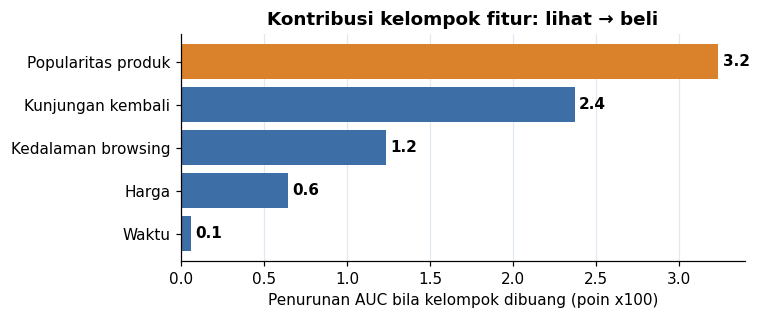

In [60]:
cols = ['pop', 'returning', 'n_products', 'repeat', 'price_rel', 'avg_price', 'n_views', 'minutes', 'hour', 'weekend']
groups = {'Kedalaman browsing': ['n_views', 'n_products', 'minutes', 'repeat'],
          'Popularitas produk': ['pop'],
          'Kunjungan kembali': ['returning'],
          'Harga': ['price_rel', 'avg_price'],
          'Waktu': ['hour', 'weekend']}
NAMA_F = {'pop': 'Popularitas produk', 'returning': 'Kunjungan kembali', 'price_rel': 'Harga relatif kategori',
          'avg_price': 'Harga rata-rata', 'repeat': 'Lihat produk sama berulang', 'n_products': 'Jumlah produk unik',
          'n_views': 'Jumlah event view', 'minutes': 'Durasi lihat', 'hour': 'Jam', 'weekend': 'Akhir pekan'}

def rank_features(data, target, seed=42):
    """Latih regresi logistik, lalu ukur penurunan AUC (data uji) per fitur dan per kelompok."""
    X = data[cols].copy()
    for k in ['n_views', 'n_products', 'minutes', 'avg_price', 'price_rel']:
        X[k] = np.log1p(X[k])
    Xtr, Xte, ytr, yte = train_test_split(X, data[target], test_size=.25, random_state=seed, stratify=data[target])
    def fit_auc(c):
        sc = StandardScaler().fit(Xtr[c])
        m = LogisticRegression(max_iter=1000).fit(sc.transform(Xtr[c]), ytr)
        return roc_auc_score(yte, m.predict_proba(sc.transform(Xte[c]))[:, 1])
    auc = fit_auc(cols)
    per_feat = pd.Series({c: auc - fit_auc([x for x in cols if x != c]) for c in cols}).sort_values(ascending=False)
    per_group = pd.Series({g: auc - fit_auc([c for c in cols if c not in m]) for g, m in groups.items()}).sort_values(ascending=False)
    return auc, per_feat, per_group

auc_all, imp_all, grp_all = rank_features(d, 'bought')
print(f'AUC lihat -> beli (data uji): {auc_all:.4f} | sesi: {len(d):,} | pembeli: {int(d["bought"].sum()):,}')
display((imp_all * 100).round(2).rename(index=NAMA_F).to_frame('penurunan AUC per fitur (poin x100)'))
display((grp_all * 100).round(2).to_frame('penurunan AUC per kelompok (poin x100)'))

def group_chart(grp, title, fname):
    fig, ax = plt.subplots(figsize=(7, 3.0)); gs = grp[::-1]
    bars = ax.barh(gs.index, gs.values * 100, color=[ORANGE if x == gs.values.max() else BLUE for x in gs.values])
    ax.bar_label(bars, fmt='%.1f', padding=3, fontweight='bold')
    ax.set_xlabel('Penurunan AUC bila kelompok dibuang (poin x100)'); ax.set_title(title); ax.grid(axis='y', visible=False)
    plt.tight_layout(); plt.savefig(f'{OUT}/{fname}'); plt.show()

group_chart(grp_all, 'Kontribusi kelompok fitur: lihat → beli', 'faktor_lihat_beli.png')

**Insight (per kelompok):** popularitas produk (3,2 poin AUC), kunjungan kembali (2,4), dan kedalaman browsing (1,2) paling membedakan sesi yang membeli dari keranjang; harga 0,6 dan waktu 0,1. Uji per fitur menyembunyikan kedalaman karena `n_views`, `n_products`, dan `minutes` saling menutupi (masing-masing hampir 0). AUC 0,69 berarti faktor-faktor ini hanya sebagian menjelaskan perilaku; sumber trafik, niat, dan tampilan halaman tidak tercatat.

### 5b. Model Keranjang → Beli (hanya sesi berkeranjang)
Tahap kedua konversi dimodelkan terpisah: di antara sesi yang sudah menambah ke keranjang, faktor apa yang membedakan yang membeli dari yang meninggalkan keranjang? Fitur tetap dihitung dari view sebelum keranjang pertama.

AUC keranjang -> beli (data uji): 0.5684 | sesi berkeranjang: 24,868 | membeli: 12,216 (49.1%)


,penurunan AUC per fitur (poin x100)
Kunjungan kembali,1.49
Jam,0.18
Akhir pekan,0.08
Durasi lihat,0.08
Lihat produk sama berulang,0.02
Jumlah event view,0.00
Jumlah produk unik,-0.00
Popularitas produk,-0.00
Harga relatif kategori,-0.03
Harga rata-rata,-0.15


,penurunan AUC per kelompok (poin x100)
Harga,1.76
Kunjungan kembali,1.49
Kedalaman browsing,0.56
Waktu,0.27
Popularitas produk,-0.00


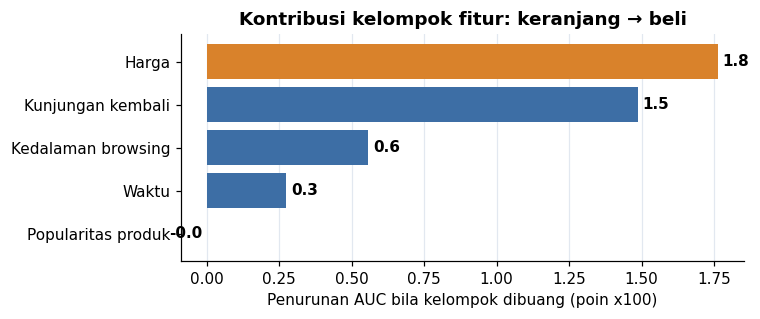


Keranjang -> beli menurut returning:


,sesi,keranjang_%,beli_dari_keranjang_%
returning,,,
0,222670,7.8,46.8
1,46204,16.0,54.5



Keranjang -> beli menurut views_bin:


,sesi,keranjang_%,beli_dari_keranjang_%
views_bin,,,
1,206379,8.0,49.0
2,37318,12.1,48.4
3,12096,14.4,49.0
4-5,7865,15.7,49.0
6-10,3916,16.9,54.8
>10,1300,17.4,58.0



Keranjang -> beli menurut pop_q:


,sesi,keranjang_%,beli_dari_keranjang_%
pop_q,,,
Q1 paling jarang dilihat,68571,4.5,49.9
Q2,65867,6.6,50.3
Q3,67248,9.4,52.0
Q4 paling populer,67188,16.5,46.8



Keranjang -> beli menurut price_q:


,sesi,keranjang_%,beli_dari_keranjang_%
price_q,,,
Q1 termurah,53886,7.1,58.0
Q2,53664,7.0,51.7
Q3,54044,7.8,50.7
Q4,53646,11.6,46.4
Q5 termahal,53634,12.8,44.3


In [61]:
dc = d[d['carted'] == 1].copy()
auc_c, imp_c, grp_c = rank_features(dc, 'bought')
print(f'AUC keranjang -> beli (data uji): {auc_c:.4f} | sesi berkeranjang: {len(dc):,} | membeli: {int(dc["bought"].sum()):,} ({dc["bought"].mean():.1%})')
display((imp_c * 100).round(2).rename(index=NAMA_F).to_frame('penurunan AUC per fitur (poin x100)'))
display((grp_c * 100).round(2).to_frame('penurunan AUC per kelompok (poin x100)'))
group_chart(grp_c, 'Kontribusi kelompok fitur: keranjang → beli', 'faktor_keranjang_beli.png')

for col in ['returning', 'views_bin', 'pop_q', 'price_q']:
    t = rate_table(col)
    print(f'\nKeranjang -> beli menurut {col}:'); display(t[['sesi', 'keranjang_%', 'beli_dari_keranjang_%']])

**Insight:** di antara sesi berkeranjang, model hampir tidak bisa membedakan yang membeli dari yang meninggalkan keranjang (AUC 0,57), jadi alasan keranjang ditinggalkan sebagian besar tidak terjelaskan oleh perilaku browsing. Faktor terbesar adalah harga (1,8 poin) dan kunjungan kembali (1,5): keranjang pada kuintil harga termahal dibeli 44,3% vs 58,0% pada termurah, dan kunjungan kembali membeli 54,5% vs 46,8%. Popularitas produk, yang paling kuat di tahap lihat ke keranjang, tidak berpengaruh di tahap ini.

#### Kesimpulan BQ4
Dua tahap punya penggerak berbeda. Tahap lihat ke keranjang digerakkan oleh popularitas produk, kunjungan kembali, dan kedalaman browsing. Tahap keranjang ke beli terutama berkaitan dengan harga dan kunjungan kembali, dengan daya prediksi rendah (AUC 0,57). Log tidak memuat alasan checkout (ongkos kirim, metode bayar, stok), sehingga penyebab sebenarnya perlu diuji, bukan disimpulkan.

In [62]:
# @title Banner Section 06
banner('Section 06', 'Business Insight & Rekomendasi',
       'Jawaban atas business question, simulasi skenario, usulan tindakan, dan keterbatasan analisis.',
       accent='#8FD8D3', end='#3D6EA5')

### 6a. Simulasi Skenario Dampak (asumsi eksplisit, bukan prediksi)
Tiga skenario menghitung tambahan pembelian jika sebagian sesi berperilaku seperti kelompok pembanding. Asumsinya **kausal** (sesi yang dipindahkan akan berperilaku seperti kelompok tujuan), padahal data hanya membuktikan asosiasi. Angka ini dipakai untuk menentukan prioritas uji, bukan untuk meramal hasil.

In [63]:
base_buy = int(d['bought'].sum())

# Skenario 1: 10% kunjungan pertama dengan 1 view berpindah ke perilaku kunjungan pertama dengan 2+ view
s1 = d[(d['single'] == 1) & (d['returning'] == 0)]
r_1view = s1['bought'].mean(); r_2plus = d[(d['single'] == 0) & (d['returning'] == 0)]['bought'].mean()
move = 0.10
add1 = len(s1) * move * (r_2plus - r_1view)

# Skenario 2: 10% keranjang yang ditinggalkan berubah menjadi pembelian
add2 = AB * 0.10

# Skenario 3: sesi pada produk paling jarang dilihat (Q1) naik ke tingkat konversi Q2
q1 = d[d['pop_q'] == 'Q1 paling jarang dilihat']; q2 = d[d['pop_q'] == 'Q2']
add3 = len(q1) * (q2['bought'].mean() - q1['bought'].mean())

sim = pd.DataFrame({
    'Skenario': ['1. 10% kunjungan pertama 1 view menjadi 2+ view', '2. 10% keranjang ditinggalkan menjadi pembelian',
                 '3. Produk ekor panjang (Q1) naik ke tingkat Q2'],
    'Sesi terdampak': [int(len(s1) * move), int(AB * 0.10), len(q1)],
    'Konversi awal (%)': [r_1view * 100, np.nan, q1['bought'].mean() * 100],
    'Konversi tujuan (%)': [r_2plus * 100, np.nan, q2['bought'].mean() * 100],
    'Pembelian tambahan': [add1, add2, add3],
    '% dari pembelian saat ini': [add1 / base_buy * 100, add2 / base_buy * 100, add3 / base_buy * 100]})
display(sim.round(1))

,Skenario,Sesi terdampak,Konversi awal (%),Konversi tujuan (%),Pembelian tambahan,% dari pembelian saat ini
0,1. 10% kunjungan pertama 1 view menjadi 2+ view,17243,3.1,5.8,470.6,3.9
1,2. 10% keranjang ditinggalkan menjadi pembelian,1265,NaN,NaN,1265.2,10.4
2,3. Produk ekor panjang (Q1) naik ke tingkat Q2,68571,2.2,3.3,753.0,6.2


## Business Insight Summary

1. **Konversi lihat ke beli hanya 4,6% dan bocor di dua titik (BQ1).** Dari 269.858 sesi dengan view, 90,8% tidak pernah ke keranjang dan 49,3% sesi berkeranjang tidak membeli.
2. **Yang tidak membeli didominasi kunjungan pertama dengan satu produk (BQ2).** Segmen ini 64,1% sesi dan berkonversi 3,1%, dibanding 10,0% pada kunjungan kembali dengan 2+ view.
3. **Produk yang dilihat menentukan (BQ3).** Produk ekor panjang berkonversi 2,2% vs 7,7% untuk produk paling populer. Komputer 6,3%, peralatan rumah 2,2%.
4. **Harga bukan penghalang di awal funnel, tetapi berkaitan dengan keranjang ditinggalkan (BQ3, BQ4).** Keranjang termahal dibeli 44,3% vs 58,0% termurah; jam dan hari berpengaruh kecil.
5. **Dua tahap, dua penggerak berbeda (BQ4).** Lihat ke keranjang: popularitas produk (3,2 poin AUC), kunjungan kembali (2,4), kedalaman browsing (1,2). Keranjang ke beli: harga (1,8) dan kunjungan kembali (1,5), dengan daya prediksi rendah (AUC 0,57).

## Business Recommendation (usulan untuk diuji dengan A/B test, bukan intervensi yang sudah terbukti)

| Prioritas | Rekomendasi | Dasar data |
|---|---|---|
| 1 | **Kurangi keranjang ditinggalkan**: pengingat keranjang yang cepat (di dalam sesi), kejelasan total biaya, dan opsi pembayaran untuk keranjang bernilai tinggi | 50,9% sesi berkeranjang tidak membeli; keranjang termahal dibeli 44,3% vs 58,0%. 75% pembelian terjadi dalam 17 menit setelah view pertama. Skenario: 10% keranjang ditinggalkan menjadi pembelian menambah sekitar 1.270 pembelian (10,4%) |
| 2 | **Angkat produk ekor panjang**: rekomendasi, pencarian, bundling | Konversi 2,2% vs 7,7%. Skenario: naik ke 3,3% menambah sekitar 750 pembelian (6,2%) |
| 3 | **Perluas penjelajahan di kunjungan pertama**: produk serupa dan perbandingan sejak produk pertama dilihat | Kunjungan pertama 1 view: 64,1% sesi, konversi 3,1% vs 5,8% bila 2+ view. Skenario: 10% berpindah menambah sekitar 470 pembelian (3,9%) |
| 4 | **Dorong kunjungan kembali**: pengingat produk yang pernah dilihat | Konversi 8,7% vs 3,7%; efek sebab-akibat belum terbukti |
| 5 | **Uji dan ukur** setiap perubahan dengan konversi lihat ke beli sebagai metrik utama | Semua temuan berupa asosiasi; jam dan hari bukan prioritas |

**Keterbatasan:** (1) Nilai kosong dihapus sehingga 41,6% event dan 41% pembelian dari keranjang tidak dianalisis; hasil berlaku untuk produk dengan kategori dan brand tercatat, dan konversi pada data bersih sedikit lebih tinggi daripada seluruh toko (4,56% vs 4,25%). (2) Log tidak memuat sumber trafik, pencarian, ulasan, stok, ongkos kirim, atau metode bayar, sehingga alasan perilaku tidak terukur. (3) Semua temuan berupa asosiasi. (4) Kunjungan kembali hanya mengacu pada periode data (24 Sep 2020 sampai 28 Feb 2021) dan waktu dalam UTC. (5) Angka dampak adalah skenario dengan asumsi eksplisit, bukan prediksi. **Langkah berikutnya:** lengkapi pencatatan kategori dan brand agar produk yang kini dibuang bisa dianalisis.

In [64]:
# @title Banner Lampiran A
banner('Lampiran A', 'Analisis Pendukung Pasca-Keranjang',
       'Keranjang → beli per kategori, brand, keranjang ditinggalkan, pembelian tertunda, dan waktu ke pembelian.',
       accent='#94A3B8', end='#475569')

### A1. Keranjang → Beli per Kategori

,sesi_keranjang,sesi_beli,keranjang_ke_beli_%
category_main,,,
stationery,1686,989.0,58.66
appliances,884,468.0,52.94
auto,1059,542.0,51.18
electronics,4421,2160.0,48.86
computers,16166,7772.0,48.08
construction,681,319.0,46.84


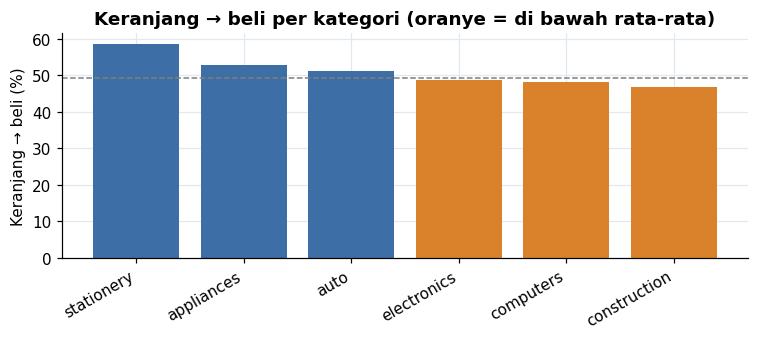

In [65]:
c_cart = fact[fact['carted'] == 1].groupby('category_main')['user_session'].nunique()
c_buy = fact[(fact['carted'] == 1) & (fact['purchased'] == 1)].groupby('category_main')['user_session'].nunique()
cat = pd.DataFrame({'sesi_keranjang': c_cart, 'sesi_beli': c_buy}).fillna(0)
cat['keranjang_ke_beli_%'] = cat['sesi_beli'] / cat['sesi_keranjang'] * 100
cat = cat[cat['sesi_keranjang'] >= MIN_SESS].sort_values('keranjang_ke_beli_%', ascending=False)
avg_cb = cat['sesi_beli'].sum() / cat['sesi_keranjang'].sum() * 100
display(cat.round(2))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(cat.index, cat['keranjang_ke_beli_%'], color=[PRIMARY if x >= avg_cb else ACCENT for x in cat['keranjang_ke_beli_%']])
ax.axhline(avg_cb, ls='--', color='gray', lw=1); ax.set_ylabel('Keranjang → beli (%)')
ax.set_title('Keranjang → beli per kategori (oranye = di bawah rata-rata)'); plt.xticks(rotation=30, ha='right')
plt.tight_layout(); plt.savefig(f'{OUT}/kategori.png'); plt.show()

**Insight:** keranjang ke beli per kategori berkisar sempit, dari 46,8% (konstruksi) sampai 58,7% (alat tulis); komputer, kategori terbesar, 48,1%. Penyebab keranjang ditinggalkan tidak terpusat pada satu kategori.

### A2. Brand dan Kekuatan Hubungannya

In [66]:
b = fact.groupby('brand').agg(pendapatan=('revenue', 'sum'))
b['sesi_lihat'] = fact[fact['viewed'] == 1].groupby('brand')['user_session'].nunique()
b['sesi_beli'] = fact[fact['purchased'] == 1].groupby('brand')['user_session'].nunique()
b = b.fillna(0)
b['porsi_pendapatan_%'] = b['pendapatan'] / b['pendapatan'].sum() * 100
b['konversi_%'] = b['sesi_beli'] / b['sesi_lihat'] * 100
display(b[b['sesi_lihat'] >= MIN_SESS].sort_values('pendapatan', ascending=False).head(10).round(2))

,pendapatan,sesi_lihat,sesi_beli,porsi_pendapatan_%,konversi_%
brand,,,,,
msi,586831.34,10009,1167.0,15.38,11.66
gigabyte,490614.13,12133,1129.0,12.86,9.31
palit,466755.82,13731,831.0,12.24,6.05
asus,300070.48,14186,834.0,7.87,5.88
sapphire,279259.38,4434,624.0,7.32,14.07
amd,156943.37,9866,575.0,4.11,5.83
canon,131586.22,10964,682.0,3.45,6.22
epson,95638.16,4231,307.0,2.51,7.26
powercolor,93294.70,2312,192.0,2.45,8.30


In [67]:
fb = fact[fact['viewed'] == 1]

def cramers(x):
    ct = pd.crosstab(x['brand'], x['purchased']).values; n = ct.sum()
    e = np.outer(ct.sum(1), ct.sum(0)) / n
    chi = ((ct - e) ** 2 / e).sum()
    return chi, np.sqrt(chi / (n * (min(ct.shape) - 1))), ct.shape[0] - 1

top8 = fb.groupby('brand')['user_session'].nunique().nlargest(8).index
chi_a, V_a, df_a = cramers(fb[fb['brand'].isin(top8)])
fc = fb[fb['category_main'] == 'computers']
top6 = fc.groupby('brand')['user_session'].nunique().nlargest(6).index
chi_c, V_c, df_c = cramers(fc[fc['brand'].isin(top6)])
print(f'8 brand teratas (semua kategori): chi2 = {chi_a:,.0f}, p = {chi2_dist.sf(chi_a, df_a):.2g}, Cramer V = {V_a:.3f}')
print(f'6 brand teratas dalam kategori computers: chi2 = {chi_c:,.0f}, p = {chi2_dist.sf(chi_c, df_c):.2g}, Cramer V = {V_c:.3f}')

8 brand teratas (semua kategori): chi2 = 844, p = 5.5e-178, Cramer V = 0.096
6 brand teratas dalam kategori computers: chi2 = 439, p = 1.1e-92, Cramer V = 0.083


**Tafsir:** hubungan brand dengan pembelian signifikan secara statistik (sampel besar) tetapi efeknya kecil (Cramér V 0,096 untuk semua kategori, 0,083 di dalam komputer). Di antara brand besar, sapphire (14,1%) dan msi (11,7%) berkonversi tertinggi, dan msi menyumbang 15,4% pendapatan. Perbandingan juga dilakukan di dalam kategori computers karena perbedaan antar brand sebagian berasal dari perbedaan kategori.

### A3. Keranjang Ditinggalkan dan Pembelian Tertunda
Definisi: baris fakta dengan `carted = 1` dan `purchased = 0`, yaitu keranjang pada kombinasi sesi × kategori × brand yang tidak berakhir pembelian. Definisi ini berbeda dari `1 - Beli/Keranjang` karena sesi bisa membeli di satu brand dan meninggalkan brand lain.

In [68]:
ab = fact[(fact['carted'] == 1) & (fact['purchased'] == 0)]
ab_sessions = ab['user_session'].nunique()
print(f'Sesi dengan keranjang ditinggalkan: {ab_sessions:,} dari {n_cart:,} ({ab_sessions / n_cart:.1%})')
print(f'Pembanding sederhana (1 - Beli/Keranjang): {1 - r_cp:.1%}')
print(f"Nilai keranjang ditinggalkan: {ab['cart_value'].sum():,.0f}")
print(f"Pendapatan: {fact['revenue'].sum():,.0f} | rata-rata per sesi beli: {fact['revenue'].sum() / n_buy_all:,.2f}")

Sesi dengan keranjang ditinggalkan: 13,155 dari 24,952 (52.7%)
Pembanding sederhana (1 - Beli/Keranjang): 50.7%
Nilai keranjang ditinggalkan: 3,414,208
Pendapatan: 3,814,818 | rata-rata per sesi beli: 289.09


**Pembelian tertunda.** Keranjang yang tidak dibeli di sesi yang sama belum tentu hilang: pengguna bisa membeli produk itu di sesi lain. Dihitung pada level pengguna × produk.

In [69]:
cp = (ev[ev['event_type'] == 'cart'].groupby(['user_id', 'product_id'])
        .agg(tc=('t', 'min'), sc=('user_session', 'first')).reset_index())
pu = ev[ev['event_type'] == 'purchase'][['user_id', 'product_id', 't', 'user_session']].rename(columns={'t': 'tp', 'user_session': 'sp'})
pp = pu.groupby(['user_id', 'product_id']).agg(tp=('tp', 'min')).reset_index()          # pembelian pertama (untuk waktu ke pembelian)

m = cp.merge(pu, on=['user_id', 'product_id'], how='left')
m = (m[m['tp'].isna() | (m['tp'] >= m['tc'])].sort_values('tp')
       .drop_duplicates(['user_id', 'product_id'], keep='first'))                       # pembelian pertama pada atau setelah keranjang
bought_m = m['tp'].notna(); same = bought_m & (m['sp'] == m['sc']); ns = ~same
delay = {'Keranjang (pengguna x produk)': len(cp),
         'Dibeli di sesi yang sama (%)': same.mean() * 100,
         'Dibeli di sesi lain setelahnya (%)': (bought_m & ~same).mean() * 100,
         'Tidak dibeli (%)': (~bought_m).mean() * 100,
         'Dari yang tidak dibeli di sesi yang sama, dibeli kemudian (%)': (bought_m & ns).sum() / ns.sum() * 100}
display(pd.Series(delay).round(1).to_frame('nilai'))

,nilai
Keranjang (pengguna x produk),26580.0
Dibeli di sesi yang sama (%),44.7
Dibeli di sesi lain setelahnya (%),4.7
Tidak dibeli (%),50.7
"Dari yang tidak dibeli di sesi yang sama, dibeli kemudian (%)",8.4


**Insight:** 52,7% sesi berkeranjang tidak berakhir pembelian pada kombinasi kategori × brand yang sama (nilai keranjang 3,41 juta vs pendapatan 3,81 juta, mata uang tidak dinyatakan di data), di atas pembanding sederhana 50,7%. Tidak semua keranjang itu hilang: dari keranjang (pengguna × produk) yang tidak dibeli di sesi yang sama, 8,4% dibeli kemudian di sesi lain, sehingga angka keranjang ditinggalkan melebih-lebihkan kehilangan sebenarnya.

### A4. Waktu ke Pembelian (time-to-purchase)
Waktu dari tampilan pertama sampai pembelian pertama untuk produk yang sama (level pengguna × produk), mengabaikan batas sesi.

Pasangan pengguna x produk: 13,571
Median 4.5 menit | 25% dalam 2.0 menit | 75% dalam 17.4 menit | 10% terlama lebih dari 477.4 menit | maksimum 110 hari


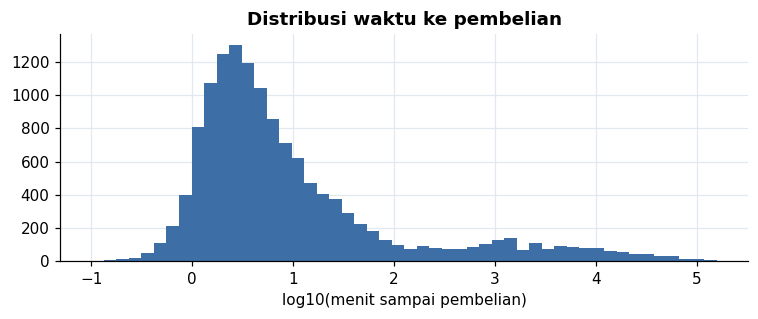

In [70]:
v1 = ev[ev['event_type'] == 'view'].groupby(['user_id', 'product_id'])['t'].min().rename('tv')
pairs = pd.concat([v1, pp.set_index(['user_id', 'product_id'])['tp']], axis=1, join='inner')
pairs = pairs[(pairs['tp'] - pairs['tv']) >= pd.Timedelta(0)].copy()
pairs['menit'] = (pairs['tp'] - pairs['tv']).dt.total_seconds() / 60
qq = pairs['menit'].quantile([.25, .5, .75, .9]).round(1)
print(f'Pasangan pengguna x produk: {len(pairs):,}')
print(f"Median {qq[.5]} menit | 25% dalam {qq[.25]} menit | 75% dalam {qq[.75]} menit | 10% terlama lebih dari {qq[.9]} menit | maksimum {pairs['menit'].max() / 1440:.0f} hari")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(pairs['menit'].clip(lower=0.1)), bins=50, color=PRIMARY)
ax.set_xlabel('log10(menit sampai pembelian)'); ax.set_title('Distribusi waktu ke pembelian')
plt.tight_layout(); plt.savefig(f'{OUT}/time_to_purchase.png'); plt.show()

In [71]:
prod_cat = ev.drop_duplicates('product_id').set_index('product_id')['category_main']
pr = pairs.reset_index(); pr['category_main'] = pr['product_id'].map(prod_cat)
ttc = pr.groupby('category_main')['menit'].agg(n='size', median='median', q90=lambda x: x.quantile(.9))
ttc = ttc[ttc['n'] >= 200].join(cat['keranjang_ke_beli_%'], how='inner').sort_values('q90', ascending=False)
display(ttc.round(1))
print('Korelasi Spearman q90 waktu ke pembelian vs keranjang->beli per kategori:',
      round(ttc['q90'].corr(ttc['keranjang_ke_beli_%'], method='spearman'), 2), f'(n = {len(ttc)} kategori, indikatif saja)')

,n,median,q90,keranjang_ke_beli_%
category_main,,,,
auto,534,5.0,921.6,51.2
construction,315,6.9,748.0,46.8
appliances,480,5.7,551.8,52.9
electronics,2282,4.7,505.3,48.9
computers,8717,4.4,440.9,48.1
stationery,1185,4.0,209.6,58.7


Korelasi Spearman q90 waktu ke pembelian vs keranjang->beli per kategori: -0.31 (n = 6 kategori, indikatif saja)


**Insight:** keputusan membeli cepat. Median 4,5 menit dari tampilan pertama ke pembelian, 75% dalam 17,4 menit, dan hanya 10% terlama melewati sekitar 8 jam (477 menit). Korelasi waktu ke pembelian dengan keranjang ke beli per kategori lemah dan hanya berdasar 6 kategori (Spearman -0,31, indikatif). Implikasinya, pengingat yang dikirim berjam-jam kemudian menyasar minoritas pembeli; intervensi di dalam sesi lebih relevan.

### Output Akhir: Data Bersih dan Grafik
Notebook ini menyimpan satu CSV data, yaitu `events_cleaned.csv` (event-level, **tanpa nilai kosong**), serta gambar-gambar chart PNG yang digunakan dalam analisis. Tabel `fact` dan `d` hanya dibuat di memori untuk perhitungan. Jalankan cell ini paling akhir.

In [72]:
# Hapus CSV lama dari versi sebelumnya (jika masih tersisa); file PNG tidak disentuh.
for old_csv in ['fact_funnel.csv', 'fact_session.csv', 'rekonsiliasi.csv']:
    old_path = os.path.join(OUT, old_csv)
    if os.path.exists(old_path):
        os.remove(old_path)

clean_csv_path = os.path.join(OUT, 'events_cleaned.csv')
events_cleaned_export.to_csv(clean_csv_path, index=False, date_format='%Y-%m-%d %H:%M:%S%z')

chk = events_cleaned_export
print('CSV data bersih:', clean_csv_path)
print(f'Jumlah event bersih: {len(chk):,}')
print(f"Event view dalam data bersih: {(chk['event_type'] == 'view').sum():,}")
print(f"Sesi unik yang memiliki view: {chk.loc[chk['event_type'] == 'view', 'user_session'].nunique():,}")
print('Total nilai kosong di file bersih:', int(chk.isna().sum().sum()))
assert chk.isna().sum().sum() == 0, 'Masih ada nilai kosong di data bersih'

charts = sorted(name for name in os.listdir(OUT) if name.lower().endswith('.png'))
print(f'Grafik tersimpan: {len(charts)} file PNG di {OUT}/')
for name in charts:
    print(' -', name)

CSV data bersih: powerbi_export/events_cleaned.csv
Jumlah event bersih: 498,199
Event view dalam data bersih: 445,620
Sesi unik yang memiliki view: 269,858
Total nilai kosong di file bersih: 0
Grafik tersimpan: 12 file PNG di powerbi_export/
 - apa_dilihat.png
 - faktor_keranjang_beli.png
 - faktor_lihat_beli.png
 - funnel.png
 - harga.png
 - kapan.png
 - kategori.png
 - kedalaman.png
 - kpi.png
 - outlier_harga.png
 - siapa_tidak_membeli.png
 - time_to_purchase.png
